In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
    "winequality-red.csv"
)

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nWine quality distribution:")
print(df["quality"].value_counts().sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual s

In [4]:
df = df.drop_duplicates()
df = df.dropna()

print("Shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

Shape after cleaning: (1359, 12)
Missing values remaining: 0


In [5]:
X = df.drop("quality", axis=1)
y = df["quality"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1359, 11)
Target shape: (1359,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Standard Scaling completed!")

Training samples: 1087
Testing samples: 272
Standard Scaling completed!


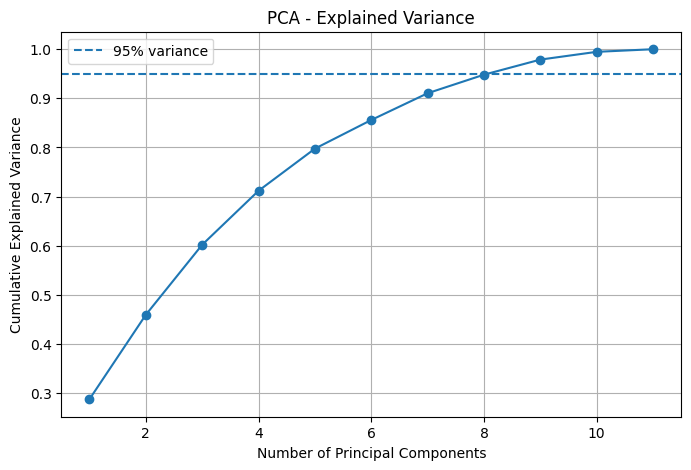

Variance explained by each component:
[0.2873 0.1719 0.1426 0.1099 0.0858 0.0584 0.0545 0.0378 0.0307 0.0158
 0.0053]
Components needed for 95% variance: 9


In [7]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid(True)
plt.legend()
plt.show()

print("Variance explained by each component:")
print(pca_full.explained_variance_ratio_.round(4))

n_components = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed for 95% variance:", n_components)

In [8]:
pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Selected principal components:", n_components)
print("Training data after PCA:", X_train_pca.shape)
print("Testing data after PCA:", X_test_pca.shape)
print(
    "Total variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original number of features: 11
Selected principal components: 9
Training data after PCA: (1087, 9)
Testing data after PCA: (272, 9)
Total variance retained: 97.89 %


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB()
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_pca, y_train)

    y_pred = model.predict(X_test_pca)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Weighted)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall (Weighted)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score (Weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1 Score (Weighted)
0,Logistic Regression,0.5882,0.5509,0.5882,0.5628
1,K-Nearest Neighbors,0.5221,0.5001,0.5221,0.5090
2,Gaussian Naive Bayes,0.5551,0.5672,0.5551,0.5455


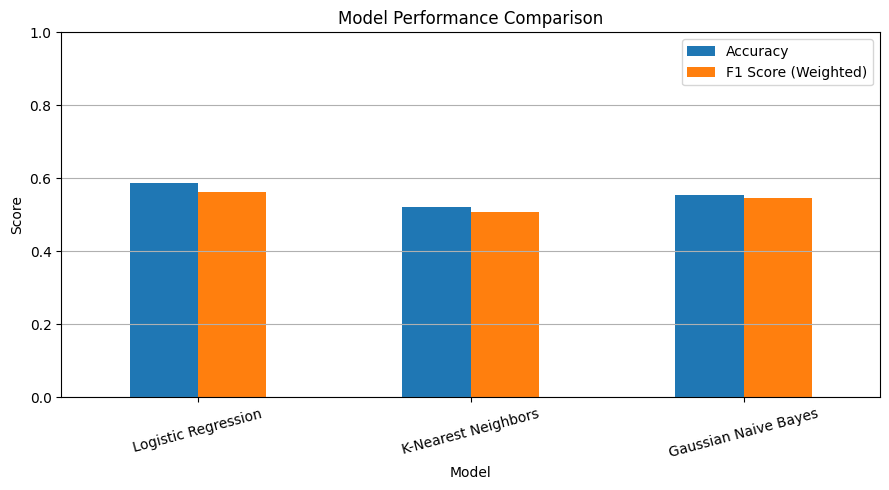

In [10]:
results_df.set_index("Model")[
    ["Accuracy", "F1 Score (Weighted)"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

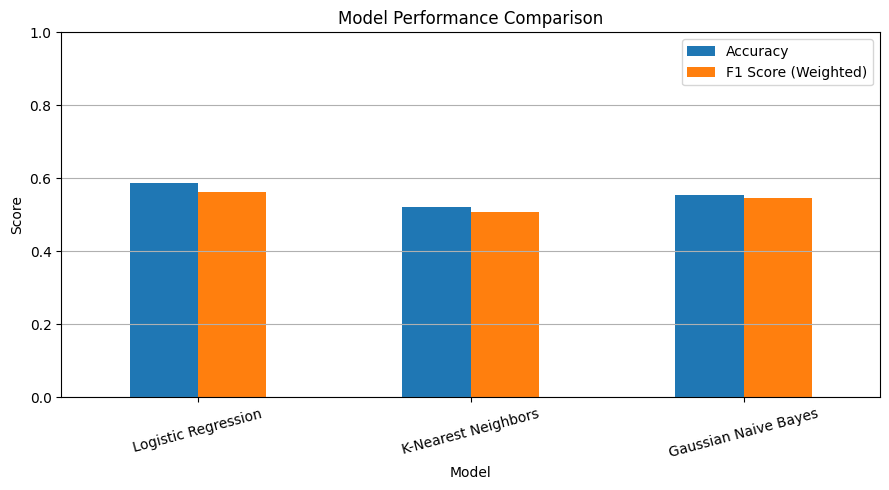

In [11]:
results_df.set_index("Model")[
    ["Accuracy", "F1 Score (Weighted)"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [12]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test_pca)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.64      0.74      0.69       116
           6       0.53      0.60      0.56       107
           7       0.56      0.30      0.39        33
           8       0.00      0.00      0.00         3

    accuracy                           0.59       272
   macro avg       0.29      0.27      0.27       272
weighted avg       0.55      0.59      0.56       272


K-Nearest Neighbors
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.20      0.09      0.12        11
           5       0.60      0.66      0.63       116
           6       0.48      0.51      0.50       107
           7       0.38      0.30      0.34        33
           8       0.00      0.00      0.00         3

    accuracy                       

In [13]:
best_model_row = results_df.loc[
    results_df["F1 Score (Weighted)"].idxmax()
]

print("Best-performing model:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("Weighted F1 Score:", round(
    best_model_row["F1 Score (Weighted)"], 4
))

print(
    "\nJustification: The selected model has the highest "
    "weighted F1 score among the three evaluated models."
)

Best-performing model: Logistic Regression
Accuracy: 0.5882
Weighted F1 Score: 0.5628

Justification: The selected model has the highest weighted F1 score among the three evaluated models.


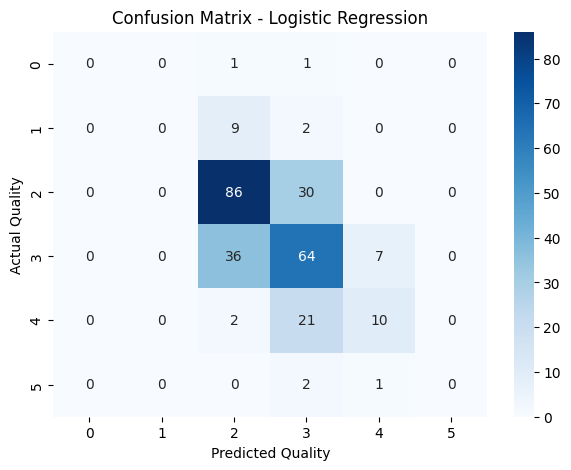

In [14]:
best_name = best_model_row["Model"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test_pca)

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.show()